# 🔴 Implement for A1 (some codes are common)

## ⚪ 1. Libraries

In [1]:
import pandas as pd
import scipy.io
import numpy as np
from scipy.io import loadmat
from sklearn.preprocessing import MinMaxScaler
from scipy.spatial.distance import cdist
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt
import seaborn as sns

## ⚪ 2. Extract indices from .csv file

In [2]:
# Define the path to your CSV file.
csv_file_path = 'annthyroidori.csv'

In [3]:
# --- Configuration ---
try:
    # --- Step 1: Load the original (raw) dataset using pandas ---
    df_original = pd.read_csv(csv_file_path) #, header=None
    print(f"Shape of the original dataset: {df_original.shape} (rows, columns)")

    # For better readability, let's assign names to the columns.
    df_original.columns = ['c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'label']

    # --- Step 2: Apply the condition to define the A1 subset ---
    condition = (df_original['c3'] >= 0) & (df_original['c3'] <= 0.025)

    # Create the A1 subset dataframe by applying the filter
    df_a1 = df_original[condition]

    # --- Step 3: Extract the indices of the rows that satisfy the condition ---
    a1_indices = df_a1.index.to_numpy()

    # --- Step 4" Checking the Number of Outliers in A1 ---
    a1_label_counts = df_a1['label'].value_counts()

    # --- Output and Verification ---
    print(f"Number of samples satisfying the A1 condition: {len(a1_indices)}")

    # Display the number of outliers in A1.
    print(f"Number of outliers in the A1 subset: {a1_label_counts}")

except Exception as e:
    print(f"An unexpected error occurred: {e}")

Shape of the original dataset: (7200, 7) (rows, columns)
Number of samples satisfying the A1 condition: 6355
Number of outliers in the A1 subset: label
1    5842
2     513
Name: count, dtype: int64


## ⚪ 3. Making X_tem from MA1 indices italicized text

In [4]:
print("Shape of A1: ", a1_indices.shape, )
print()
print("index of A1 :", a1_indices)
print()
print("type of A1: ", type(a1_indices))

Shape of A1:  (6355,)

index of A1 : [   0    2    3 ... 7197 7198 7199]

type of A1:  <class 'numpy.ndarray'>


In [5]:
# Conver ma1_indices to python list
X_tem1 = a1_indices.tolist()

## ⚪ 4. Checking .mat file

In [6]:
mat = scipy.io.loadmat('annthyroid.mat')
print(mat.keys())
print(pd.DataFrame(mat['trandata']).describe())

# mat['trandata']

dict_keys(['__header__', '__version__', '__globals__', 'trandata'])
                 0            1            2            3            4  \
count  7200.000000  7200.000000  7200.000000  7200.000000  7200.000000   
mean      0.531790     0.009172     0.108506     0.179649     0.374250   
std       0.197156     0.043357     0.042001     0.060148     0.088354   
min       0.000000     0.000000     0.000000     0.000000     0.000000   
25%       0.375000     0.001340     0.091922     0.145485     0.324074   
50%       0.562500     0.003208     0.109192     0.175585     0.370370   
75%       0.687500     0.005094     0.119777     0.205686     0.402778   
max       1.000000     1.000000     1.000000     1.000000     1.000000   

                 5            6  
count  7200.000000  7200.000000  
mean      0.173773     0.074167  
std       0.056402     0.262060  
min       0.000000     0.000000  
25%       0.145313     0.000000  
50%       0.170313     0.000000  
75%       0.195312     0.00

## ⚪ 5. Main code of 3WNCROD

In [7]:
def WNCROD(data, X_tem, lammda):

    n, m = data.shape
    X = np.zeros(n)
    X[X_tem] = 1

    D1 = m / 3
    D2 = m / 2
    D3 = 0.9 * m

    delta = np.zeros(m)
    ID = np.all(data <= 1, axis=0)
    delta[ID] = np.std(data[:, ID], axis=0) / lammda

    Lower = np.zeros((m, n))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        Lower_temp = np.min(np.maximum(1 - RM_tem, np.tile(X, (n, 1))), axis=1)
        Lower[col, :Lower_temp.shape[0]] = Lower_temp

    IB = np.tile(X, (m, 1)) - Lower
    NEB = np.min(IB, axis=0)
    NPB = IB - np.tile(NEB, (m, 1))

    n_X = int(sum(X))

    weight = np.zeros((n_X, m))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        weight_x = []

        for i in range(n_X):
            temp1 = RM_tem[X_tem[i], :]
            weight_temp = 1 - (np.sqrt((np.sum(np.minimum(temp1, X))) / n_X))
            weight_x.append(weight_temp)

        weight[:len(weight_x), col] = weight_x

    D_tem = np.zeros((n, n))

    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        D_tem += RM_tem

    NOM = m - D_tem
    X_OM = NOM[np.ix_(X_tem, X_tem)]

    NEB_num = np.zeros((n_X, m))
    Lower_num = np.zeros((n_X, m))
    NPB_num = np.zeros((n_X, m))

    for col in range(m):
        temp2 = Lower[col, :]
        temp3 = NPB[col, :]

        for i in range(n_X):
            temp1 = X_OM[i, :]
            NEB_num[i, col] = np.sum(np.minimum(NEB[X_tem], temp1 <= D1))
            NPB_num[i, col] = np.sum(np.minimum(temp3[X_tem], temp1 >= D2))
            Lower_num[i, col] = np.sum(np.minimum(temp2[X_tem], temp1 >= D3))

    MNOF = np.mean(((NEB_num + Lower_num + NPB_num) / n_X) * weight, axis=1)
    return MNOF


## ⚪ 6. Run algorythm for A1

In [ ]:
if __name__ == "__main__":

    # 1) Load data
    mat       = loadmat('annthyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X1 = full_data[:, :6]                   # First 6 columns
    y1 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features (columns 2 to 6)
    scaler = MinMaxScaler()
    X1[:, 1:] = scaler.fit_transform(X1[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda=2.0
    out_scores = WNCROD(X1, X_tem1, lammda=2.0)

    # 5) Extract true labels only for X_tem1
    y_true = y1[X_tem1]

    # 6) Compute metrics
    roc_auc1 = roc_auc_score(y_true, out_scores)
    ap1      = average_precision_score(y_true, out_scores)

    print(f"ROC-AUC: {roc_auc1:.4f}")
    print(f"Average Precision (AP): {ap1:.4f}")

    # last outputs:
    # ROC-AUC: 0.7317
    # Average Precision (AP): 0.4372

In [ ]:
# لیست λها و مقادیر متناظر ROC-AUC
lambda_list = [0.1, 0.2, 0.3, 0.4, 0.5,
               0.6, 0.7, 0.8, 0.9, 1.0,
               1.1, 1.2, 1.3, 1.4, 1.5,
               1.6, 1.7, 1.8, 1.9, 2.0]

roc_auc_list = [0.1725, 0.5688, 0.6474, 0.6315, 0.6150,
                0.5883, 0.5926, 0.5799, 0.5903, 0.6068,
                0.6236, 0.6203, 0.6717, 0.6872, 0.6942,
                0.7013, 0.7036, 0.7105, 0.7230, 0.7317]

# رسم نمودار
plt.figure(figsize=(8, 5))
plt.plot(lambda_list, roc_auc_list, marker='o', linestyle='-',
         color='C0', label='ROC-AUC')
plt.title('ROC-AUC vs λ (A1)')
plt.xlabel('λ')
plt.ylabel('ROC-AUC')
plt.xticks(lambda_list, rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 🔵 New Approach for A1

### 1. Main code of new 3WNCROD

In [ ]:
def NEW_WNCROD(data: np.ndarray, X_tem: list[int], lammda_list: list[float]) -> np.ndarray:

    n, m = data.shape
    lammda_arr = np.array(lammda_list, dtype=float)
    if lammda_arr.shape[0] != m:
        raise ValueError(f"The length of lammda_list must be equal to the #features : ({m}).")

    X = np.zeros(n, dtype=int)
    X[X_tem] = 1

    D1 = m / 3
    D2 = m / 2
    D3 = 0.9 * m

    # Calculate independent neighborhood radius for each feature
    delta = np.zeros(m, dtype=float)
    ID = np.all(data <= 1, axis=0)
    stds = np.std(data[:, ID], axis=0)
    delta[ID] = stds / lammda_arr[ID]

    Lower = np.zeros((m, n), dtype=float)
    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        Lower_temp = np.min(np.maximum(1 - RM_tem, np.tile(X, (n, 1))), axis=1)
        Lower[col, :Lower_temp.shape[0]] = Lower_temp

    # IB, NEB, NPB
    IB = np.tile(X, (m, 1)) - Lower
    NEB = np.min(IB, axis=0)
    NPB = IB - np.tile(NEB, (m, 1))

    # Weighting
    n_X = int(np.sum(X))
    weight = np.zeros((n_X, m), dtype=float)
    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        wcol = []
        for i in range(n_X):
            temp1 = RM_tem[X_tem[i], :]
            wtemp = 1 - np.sqrt(np.sum(np.minimum(temp1, X)) / n_X)
            wcol.append(wtemp)
        weight[:, col] = wcol

    # D_tem & NOM
    D_tem = np.zeros((n, n), dtype=int)
    for col in range(m):
        RM_tem = cdist(data[:, [col]], data[:, [col]], metric='cityblock') <= delta[col]
        D_tem += RM_tem.astype(int)
    NOM = m - D_tem
    X_OM = NOM[np.ix_(X_tem, X_tem)]

    # counting : NEB_num, Lower_num, NPB_num
    NEB_num = np.zeros((n_X, m), dtype=int)
    Lower_num = np.zeros((n_X, m), dtype=int)
    NPB_num = np.zeros((n_X, m), dtype=int)
    for col in range(m):
        tLower = Lower[col, :]
        tNPB   = NPB[col, :]
        for i in range(n_X):
            row_OM = X_OM[i, :]
            NEB_num[i, col]   = np.sum(np.minimum(NEB[X_tem],    row_OM <= D1))
            NPB_num[i, col]   = np.sum(np.minimum(tNPB[X_tem],   row_OM >= D2))
            Lower_num[i, col] = np.sum(np.minimum(tLower[X_tem], row_OM >= D3))

    # calculate MNOF
    NDF = (NEB_num + Lower_num + NPB_num) / n_X
    MNOF = np.mean(NDF * weight, axis=1)
    return MNOF

### 2. runing algo

In [ ]:
def feature_ablation_analysis(data, labels, X_tem, lammda_list):
    """
    Run ablation: remove each feature and re-run NEW_WNCROD.
    Return dict of AP/ROC drops compared to baseline.
    """
    from sklearn.metrics import roc_auc_score, average_precision_score

    # --- baseline with all features ---
    base_scores = NEW_WNCROD(data, X_tem, lammda_list)
    base_y = labels[X_tem]
    base_ap = average_precision_score(base_y, base_scores)
    base_roc = roc_auc_score(base_y, base_scores)

    results = {}
    n_features = data.shape[1]

    for f in range(n_features):
        # remove column f
        reduced_data = np.delete(data, f, axis=1)
        reduced_lam  = [lam for j, lam in enumerate(lammda_list) if j != f]

        scores = NEW_WNCROD(reduced_data, X_tem, reduced_lam)
        ap = average_precision_score(base_y, scores)
        roc = roc_auc_score(base_y, scores)

        results[f] = {
            "AP": ap,
            "ROC": roc,
            "AP_drop": base_ap - ap,
            "ROC_drop": base_roc - roc
        }

    return base_ap, base_roc, results


In [ ]:
if __name__ == "__main__":
    lammda = [3.1, 3.1, 3.1, 0.1, 0.1, 0.1]
    mat       = loadmat('annthyroid.mat')
    full_data = mat['trandata']
    X11 = full_data[:, :6]
    y11 = full_data[:, 6].astype(int)

    scaler = MinMaxScaler()
    X11[:, 1:] = scaler.fit_transform(X11[:, 1:])

    base_ap, base_roc, ablation_res = feature_ablation_analysis(X11, y11, X_tem1, lammda)

    print(f"Baseline AP={base_ap:.4f}, ROC={base_roc:.4f}")
    for f, vals in ablation_res.items():
        print(f"Feature {f}: AP_drop={vals['AP_drop']:.4f}, ROC_drop={vals['ROC_drop']:.4f}")


Baseline AP=0.7038, ROC=0.8929
Feature 0: AP_drop=0.6152, ROC_drop=0.6231
Feature 1: AP_drop=0.6059, ROC_drop=0.3010
Feature 2: AP_drop=0.6533, ROC_drop=0.7444
Feature 3: AP_drop=0.0158, ROC_drop=0.0512
Feature 4: AP_drop=0.0246, ROC_drop=0.0515
Feature 5: AP_drop=0.0158, ROC_drop=0.0512


In [ ]:
# this is for best lammda list for TOP AP
if __name__ == "__main__":

    lammda = [3.1, 3.1, 3.1, 0.1, 0.1, 0.1]

    # 1) Load data
    mat       = loadmat('annthyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X11 = full_data[:, :6]                   # First 6 columns
    y11 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features (columns 2 to 6)
    scaler = MinMaxScaler()
    X11[:, 1:] = scaler.fit_transform(X11[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores11 = NEW_WNCROD(X11, X_tem1, lammda)

    # 5) Extract true labels only for X_tem
    y_true11 = y11[X_tem1]

    # 6) Compute metrics
    roc_auc11 = roc_auc_score(y_true11, out_scores11)
    ap11      = average_precision_score(y_true11, out_scores11)

    print(f"ROC-AUC: {roc_auc11:.4f}")
    print(f"Average Precision (AP): {ap11:.4f}")

ROC-AUC: 0.8929
Average Precision (AP): 0.7038


In [ ]:
# this is for best lammda list for TOP ROC-AUC
if __name__ == "__main__":

    lammda = [0.3, 3.1, 2.8, 0.1, 0.1, 0.1]

    # 1) Load data
    mat       = loadmat('annthyroid.mat')
    full_data = mat['trandata']            # shape = (n_samples, 7)

    # 2) Separate features and labels
    X11 = full_data[:, :6]                   # First 6 columns
    y11 =  full_data[:, 6].astype(int)       # Column 7 (index 6)

    # 3) Normalize only the features (columns 2 to 6)
    scaler = MinMaxScaler()
    X11[:, 1:] = scaler.fit_transform(X11[:, 1:])

    # 4) Run the algorithm with the same X_tem and lammda=0.5
    out_scores11 = NEW_WNCROD(X11, X_tem1, lammda)

    # 5) Extract true labels only for X_tem
    y_true11 = y11[X_tem1]

    # 6) Compute metrics
    roc_auc11 = roc_auc_score(y_true11, out_scores11)
    ap11      = average_precision_score(y_true11, out_scores11)

    print(f"ROC-AUC: {roc_auc11:.4f}")
    print(f"Average Precision (AP): {ap11:.4f}")

ROC-AUC: 0.8980
Average Precision (AP): 0.6594


> 👉👉 **Its ok and it works. we claimed the same result for same lammda.** ✅
>
> **Now we will loking for improvments by searching for best lammda list. 👇👇👇**

### 3. Greedy Search fo lammda's **(1 Candidate List)**

In [ ]:
def greedy_search_lambdas(X: np.ndarray,
                          y: np.ndarray,
                          X_tem: list[int],
                          candidates: list[float],
                          metric_name: str = 'AP'):

    m = X.shape[1]
    # Start with all λ's equal to 1
    best_lambdas = np.ones(m, dtype=float)
    metric_matrix = np.zeros((m, len(candidates)), dtype=float)
    y_true = y[X_tem1]

    # Selecting the criterion function
    if metric_name.upper() == 'AP':
        metric_func = average_precision_score
    elif metric_name.upper() == 'ROC':
        metric_func = roc_auc_score
    else:
        raise ValueError("metric_name must be 'AP' or 'ROC'")

    # Loop over each feature
    for j in range(m):
        best_val = -np.inf
        best_c = best_lambdas[j]
        for idx_c, c in enumerate(candidates):
            # Set λ_j = c and other λs constant
            best_lambdas[j] = c
            # Calculate output score
            scores = NEW_WNCROD(X, X_tem, best_lambdas)
            # Calculation of criteria
            val = metric_func(y_true, scores)
            metric_matrix[j, idx_c] = val
            if val > best_val:
                best_val = val
                best_c = c
        # After testing all candidates for feature j, fix λ_j on the best value
        best_lambdas[j] = best_c

    return best_lambdas, metric_matrix


=== Best Lambdas for AP ===
[2.4 2.5 2.5 0.1 0.1 0.1]
=== Best Lambdas for ROC-AUC ===
[0.3 2.5 2.5 0.1 0.1 0.1]


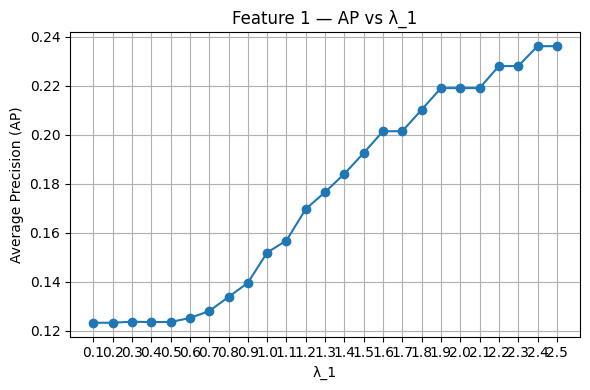

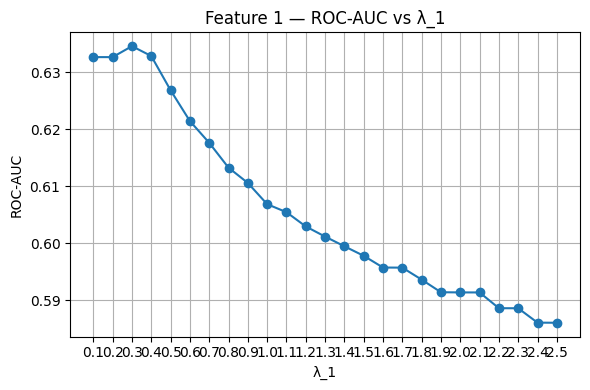

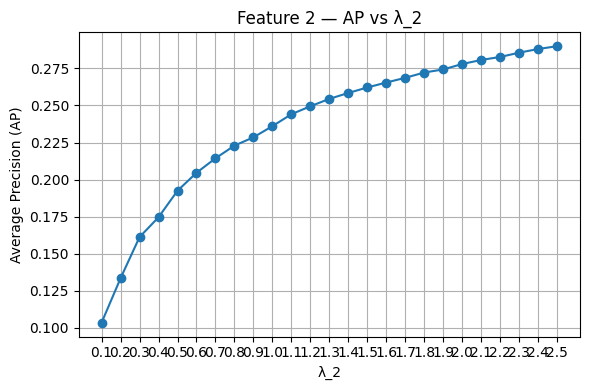

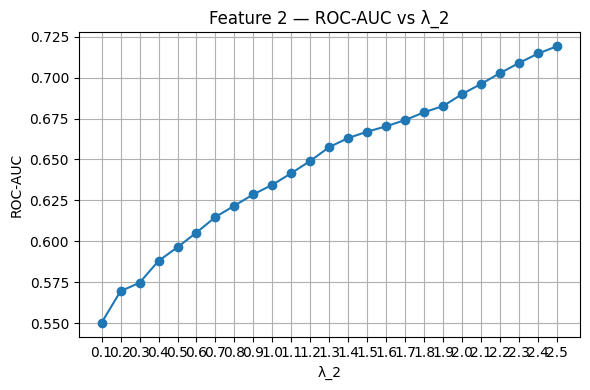

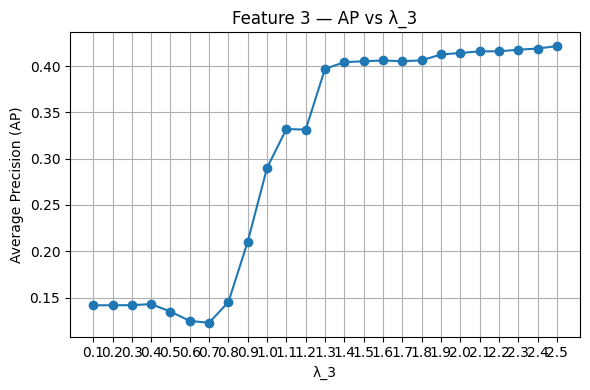

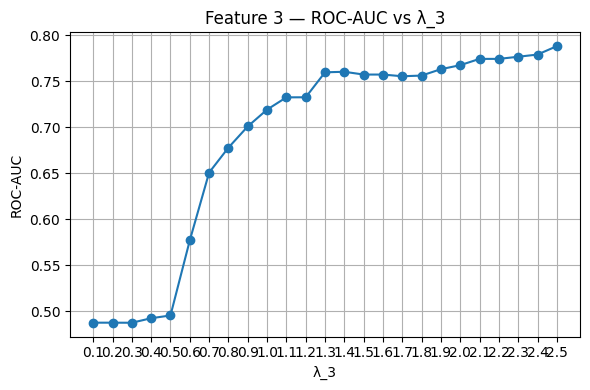

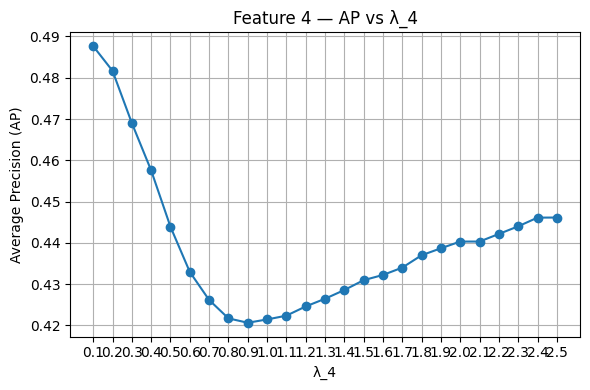

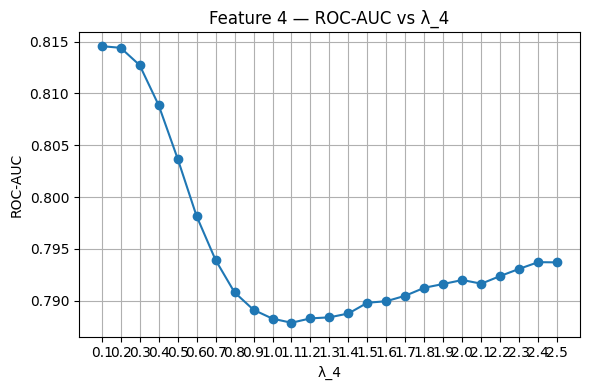

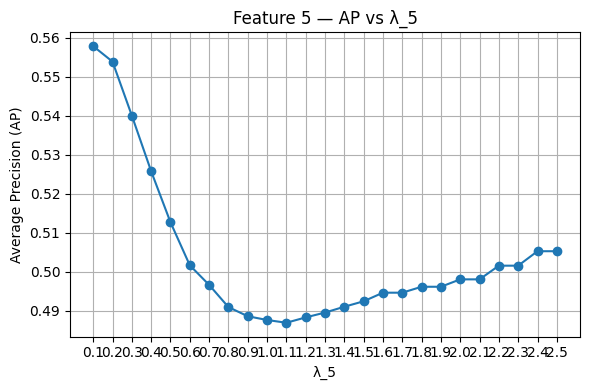

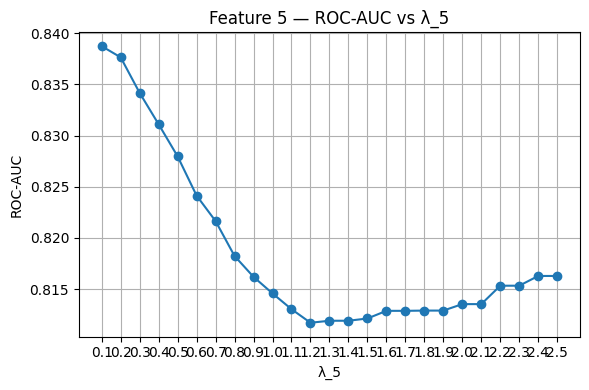

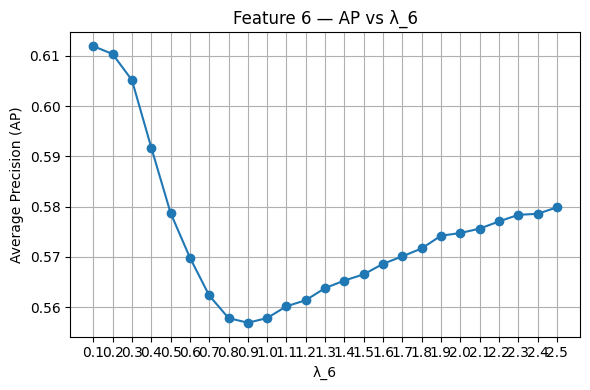

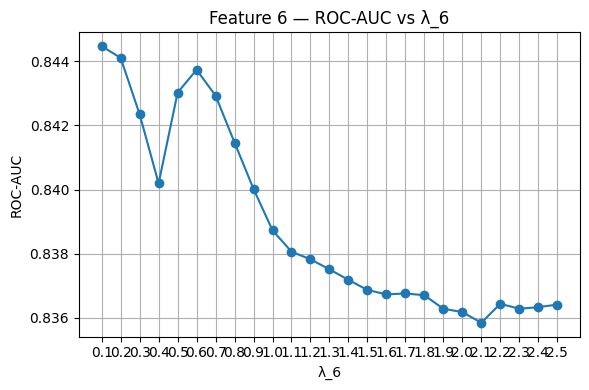

In [ ]:
if __name__ == "__main__":
    # =======================
    #1) Setting the parameters
     # =======================
    candidates = [0.1, 0.2, 0.3, 0.4, 0.5,
                  0.6, 0.7, 0.8, 0.9, 1.0,
                  1.1, 1.2, 1.3, 1.4, 1.5,
                  1.6, 1.7, 1.8, 1.9, 2.0,
                  2.1, 2.2, 2.3, 2.4, 2.5]
    # List of candidate values for λ

    # =======================
    #2) Loading and Preprocessing
    # =======================
    mat = loadmat('annthyroid.mat')
    full_data = mat['trandata']       # shape = (n_samples, 7)
    X11 = full_data[:, :6]
    y11 = full_data[:, 6].astype(int)

    scaler = MinMaxScaler()
    X11[:, 1:] = scaler.fit_transform(X11[:, 1:])

    # X_tem

    # ================================
    #3) Greedy search for AP
    # ================================
    best_lams_ap, metrics_ap = greedy_search_lambdas(
        X11, y11, X_tem1, candidates, metric_name='AP'
    )
    print("=== Best Lambdas for AP ===")
    print(best_lams_ap)

    # ================================
    #4) Greedy search for ROC-AUC
    # ================================
    best_lams_roc, metrics_roc = greedy_search_lambdas(
        X11, y11, X_tem1, candidates, metric_name='ROC'
    )
    print("=== Best Lambdas for ROC-AUC ===")
    print(best_lams_roc)

    # ============================================
    #5) Draw graphs for each feature and each criterion
    # ============================================
    m = X11.shape[1]
    for j in range(m):
        # Chart for AP
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_ap[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — AP vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("Average Precision (AP)")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

        # Chart for ROC-AUC
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_roc[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — ROC-AUC vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("ROC-AUC")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

=== Best Lambdas for AP ===
[3.1 3.1 3.1 0.1 0.1 0.1]
=== Best Lambdas for ROC-AUC ===
[0.3 3.1 2.8 0.1 0.1 0.1]


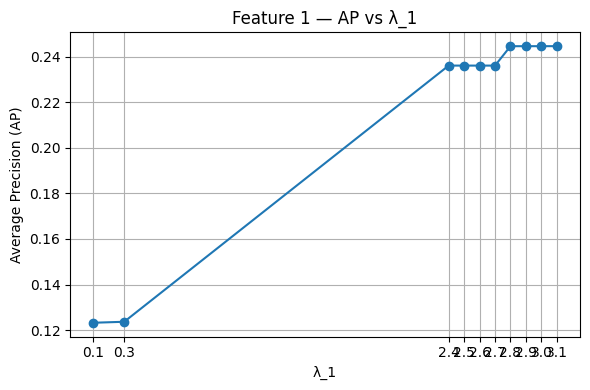

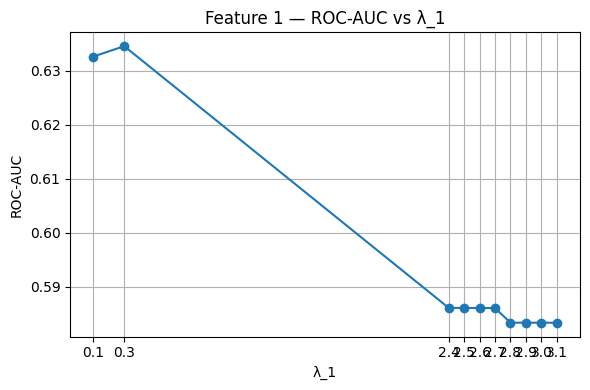

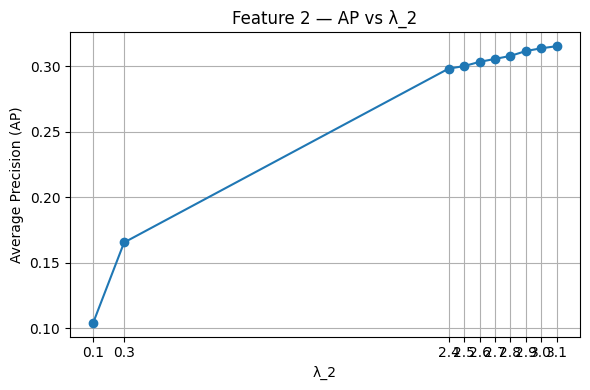

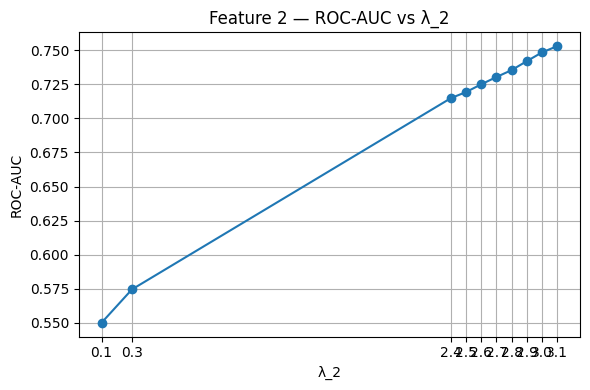

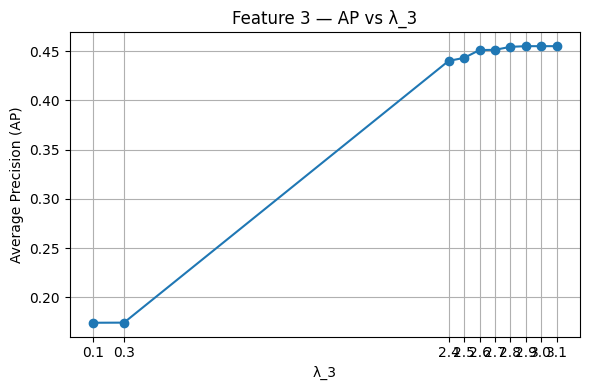

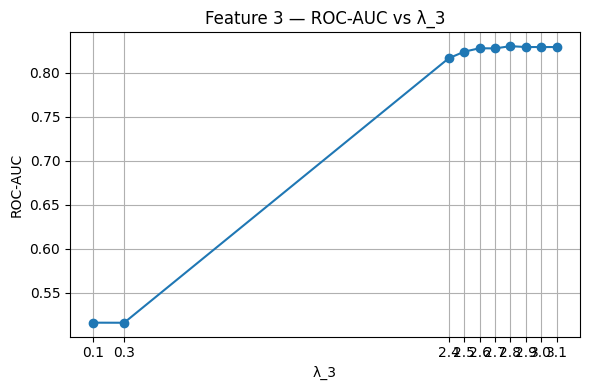

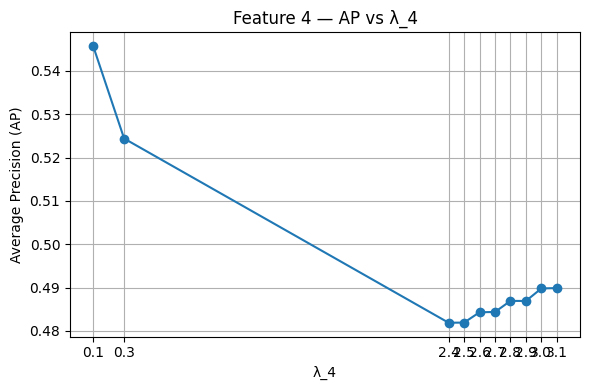

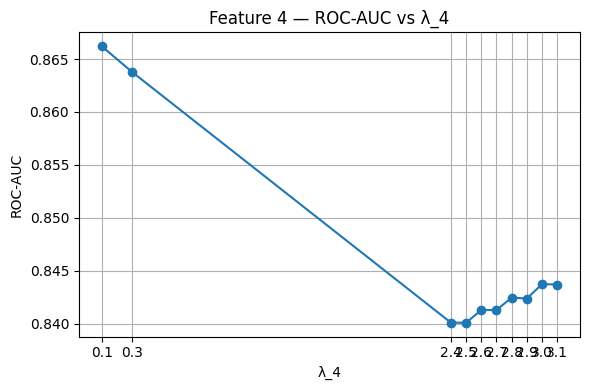

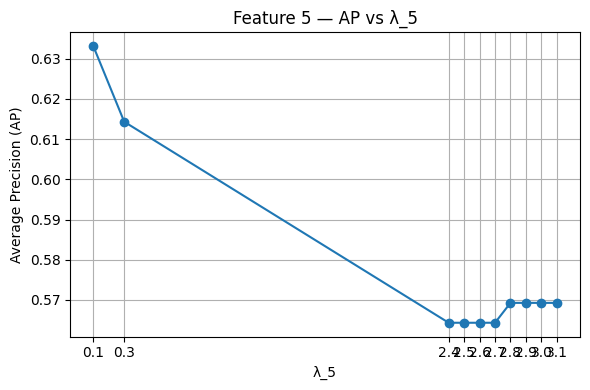

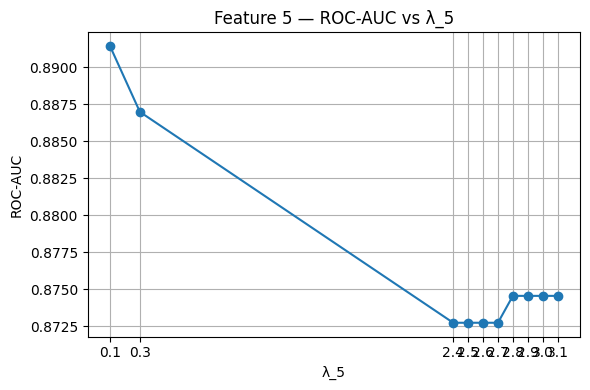

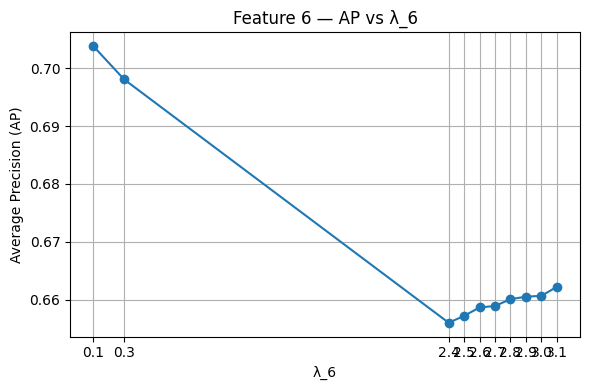

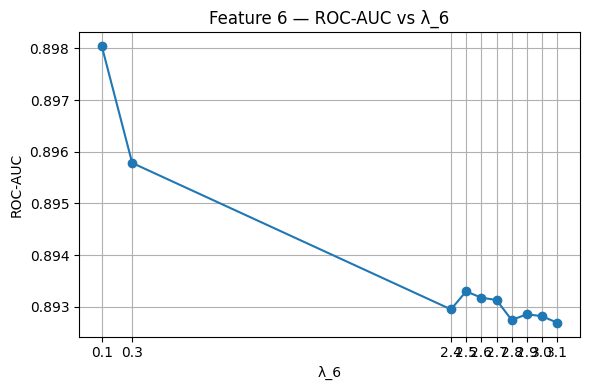

In [ ]:
if __name__ == "__main__":
    # =======================
    #1) Setting the parameters
     # =======================
    candidates = [0.1, 0.3, 2.4, 2.5, 2.6,
                  2.7, 2.8, 2.9, 3.0, 3.1,]
    # List of candidate values for λ

    # =======================
    #2) Loading and Preprocessing
    # =======================
    mat = loadmat('annthyroid.mat')
    full_data = mat['trandata']       # shape = (n_samples, 7)
    X11 = full_data[:, :6]
    y11 = full_data[:, 6].astype(int)

    scaler = MinMaxScaler()
    X11[:, 1:] = scaler.fit_transform(X11[:, 1:])

    # X_tem

    # ================================
    #3) Greedy search for AP
    # ================================
    best_lams_ap, metrics_ap = greedy_search_lambdas(
        X11, y11, X_tem1, candidates, metric_name='AP'
    )
    print("=== Best Lambdas for AP ===")
    print(best_lams_ap)

    # ================================
    #4) Greedy search for ROC-AUC
    # ================================
    best_lams_roc, metrics_roc = greedy_search_lambdas(
        X11, y11, X_tem1, candidates, metric_name='ROC'
    )
    print("=== Best Lambdas for ROC-AUC ===")
    print(best_lams_roc)

    # ============================================
    #5) Draw graphs for each feature and each criterion
    # ============================================
    m = X11.shape[1]
    for j in range(m):
        # Chart for AP
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_ap[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — AP vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("Average Precision (AP)")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()

        # Chart for ROC-AUC
        plt.figure(figsize=(6, 4))
        plt.plot(candidates, metrics_roc[j, :], marker='o', linestyle='-')
        plt.title(f"Feature {j+1} — ROC-AUC vs λ_{j+1}")
        plt.xlabel(f"λ_{j+1}")
        plt.ylabel("ROC-AUC")
        plt.grid(True)
        plt.xticks(candidates)
        plt.tight_layout()
        plt.show()